In [1]:
from pathlib import Path
import matplotlib.pyplot as plt

import random
import numpy as np
import pandas as pd
import torch

GLOBAL_SEED = 420
random.seed(GLOBAL_SEED)
np.random.seed(GLOBAL_SEED)
torch.manual_seed(GLOBAL_SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(GLOBAL_SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = True
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [34]:
# hiperparameters
embedding_dim = 6
epochs = 501

In [35]:
dataset = Path("dataset.txt").read_text(encoding="utf-8")
dataset

'mip likes dax\nmip likes zof\n\ntig likes dax\ntig likes zof\n\nral owns tek\nral owns mek\n\nred is color\nblue is color\ngreen is color\n\ncat is animal\ndog is animal\nbird is animal'

In [36]:
sentences = [line.split() for line in dataset.splitlines() if line.strip()]
word_columns = [f"word_{i}" for i in range(1, max(map(len, sentences)) + 1)]
sentence_table = pd.DataFrame(sentences, columns=word_columns)
sentence_table


,word_1,word_2,word_3
0,mip,likes,dax
1,mip,likes,zof
2,tig,likes,dax
3,tig,likes,zof
4,ral,owns,tek
5,ral,owns,mek
6,red,is,color
7,blue,is,color
8,green,is,color
9,cat,is,animal


In [37]:
# create a vocabulary of unique words
vocabulary = sorted({word for sentence in sentences for word in sentence})
vocab_size = len(vocabulary)
print(f"Vocabulary size: {vocab_size}")
print(f"Vocabulary: {vocabulary}")

Vocabulary size: 18
Vocabulary: ['animal', 'bird', 'blue', 'cat', 'color', 'dax', 'dog', 'green', 'is', 'likes', 'mek', 'mip', 'owns', 'ral', 'red', 'tek', 'tig', 'zof']


In [38]:
vocabulary = list(vocabulary)
def encode(text):
    return [vocabulary.index(word) for word in text.split()]
def decode(indices):
    return " ".join(vocabulary[i] for i in indices)

print(encode("blue is color"))
print(decode(encode("blue is color")))

[2, 8, 4]
blue is color


In [39]:
class SmallWordPredictor(torch.nn.Module):
    def __init__(self, vocab_size, embedding_dim):
        super().__init__()
        self.in_embedding = torch.nn.Embedding(vocab_size, embedding_dim)
        self.out_embedding = torch.nn.Embedding(vocab_size, embedding_dim)

        self.out_embedding.weight = self.in_embedding.weight  # weight tying
    
    def forward(self, x):
        x = self.in_embedding(x)  # (B, T, C)
        return x @ self.out_embedding.weight.T  # (B, T, vocab_size)

In [40]:
# take first two words as x and last two words as y for training
x = torch.tensor([encode(" ".join(words)) for words in sentence_table.iloc[:, :2].to_numpy()], dtype=torch.long)
y = torch.tensor([encode(" ".join(words)) for words in sentence_table.iloc[:, -2:].to_numpy()], dtype=torch.long)
x = x.to(device)
y = y.to(device)
print(x[0], y[0])

tensor([11,  9], device='cuda:0') tensor([9, 5], device='cuda:0')


In [41]:
model = SmallWordPredictor(vocab_size, embedding_dim).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-2)
model = model.to(device)

print(model)
print(f"Number of parameters: {sum(p.numel() for p in model.parameters())}")

SmallWordPredictor(
  (in_embedding): Embedding(18, 6)
  (out_embedding): Embedding(18, 6)
)
Number of parameters: 108


In [42]:
# visualize paiwise cosine similarity of word embeddings
def visualize_embeddings(model, vocabulary):
    embeddings = model.in_embedding.weight.data.cpu().numpy()
    cosine_similarities = np.dot(embeddings, embeddings.T)
    norms = np.linalg.norm(embeddings, axis=1)
    cosine_similarities /= norms[:, None]
    cosine_similarities /= norms[None, :]
    
    plt.figure(figsize=(10, 8))
    plt.imshow(cosine_similarities, cmap='viridis', interpolation='nearest')
    plt.colorbar()
    plt.xticks(ticks=np.arange(len(vocabulary)), labels=vocabulary, rotation=90)
    plt.yticks(ticks=np.arange(len(vocabulary)), labels=vocabulary)
    plt.title("Pairwise Cosine Similarity of Word Embeddings")
    plt.show()

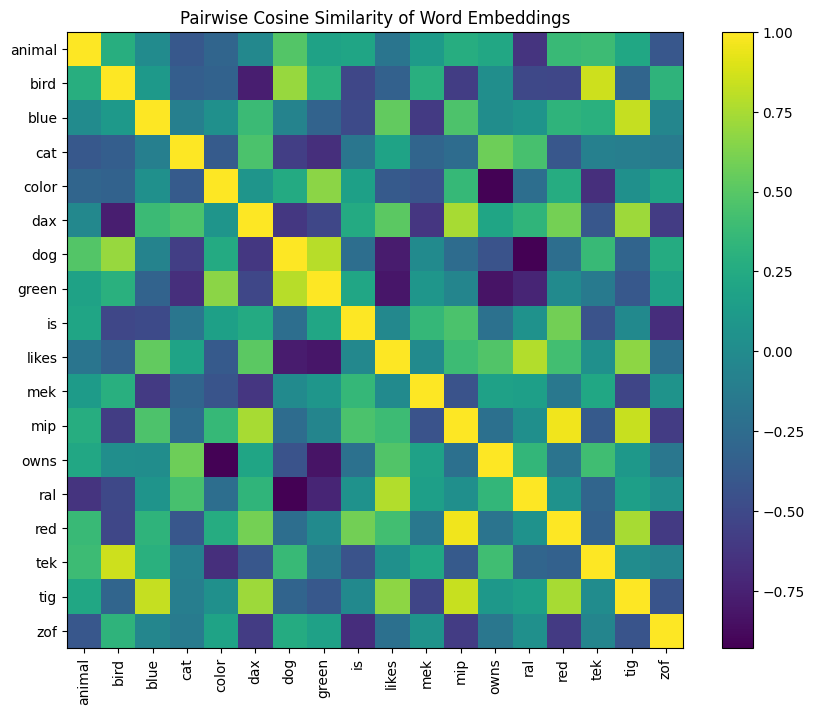

Epoch 0, Loss: 4.6789


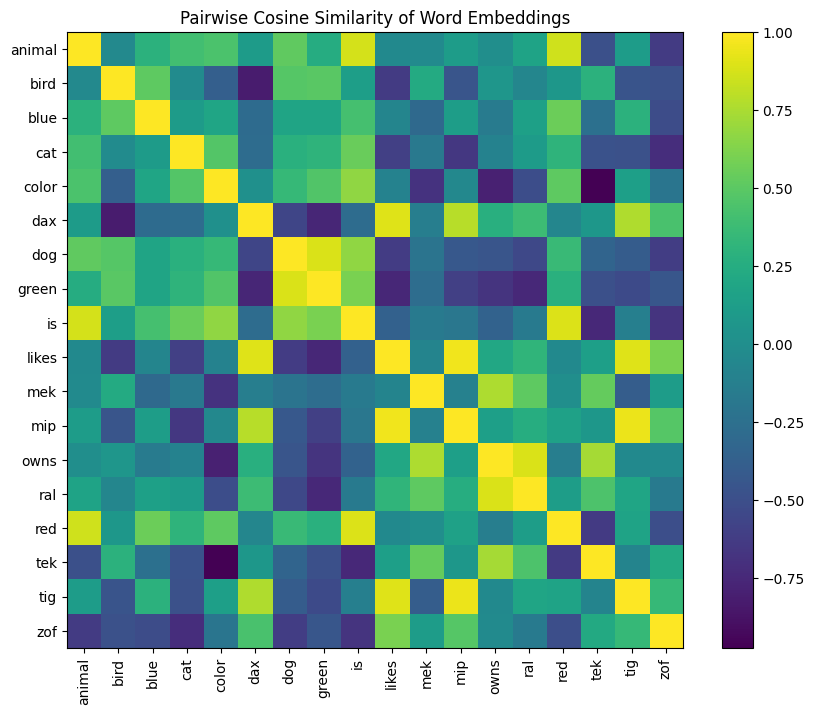

Epoch 100, Loss: 1.4651


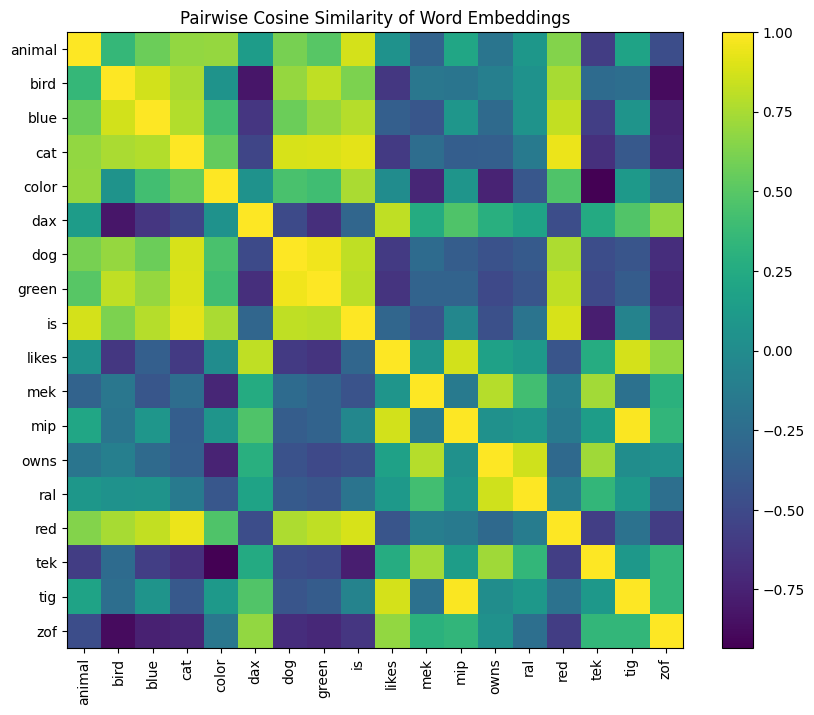

Epoch 200, Loss: 0.9356


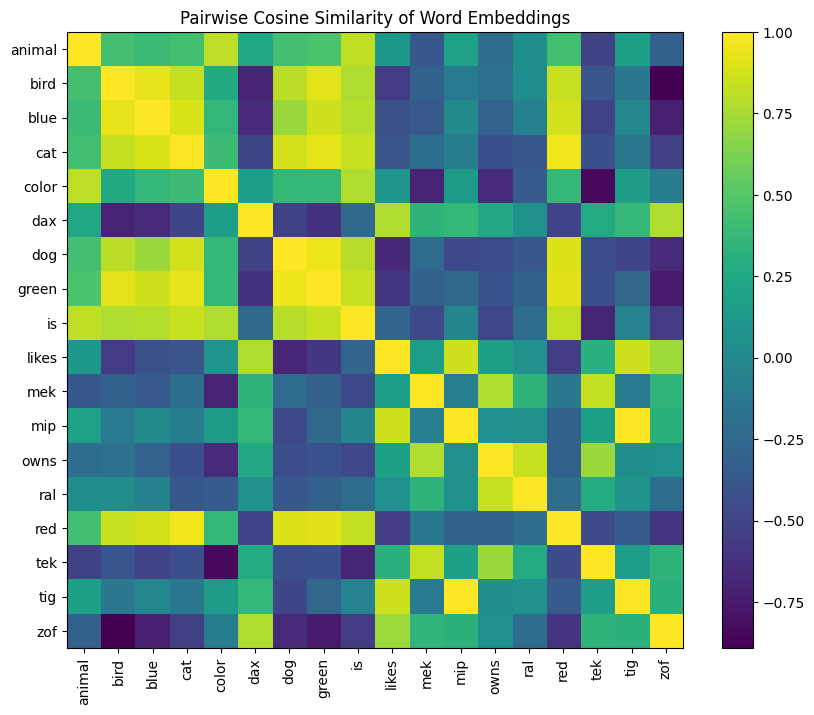

Epoch 300, Loss: 0.6148


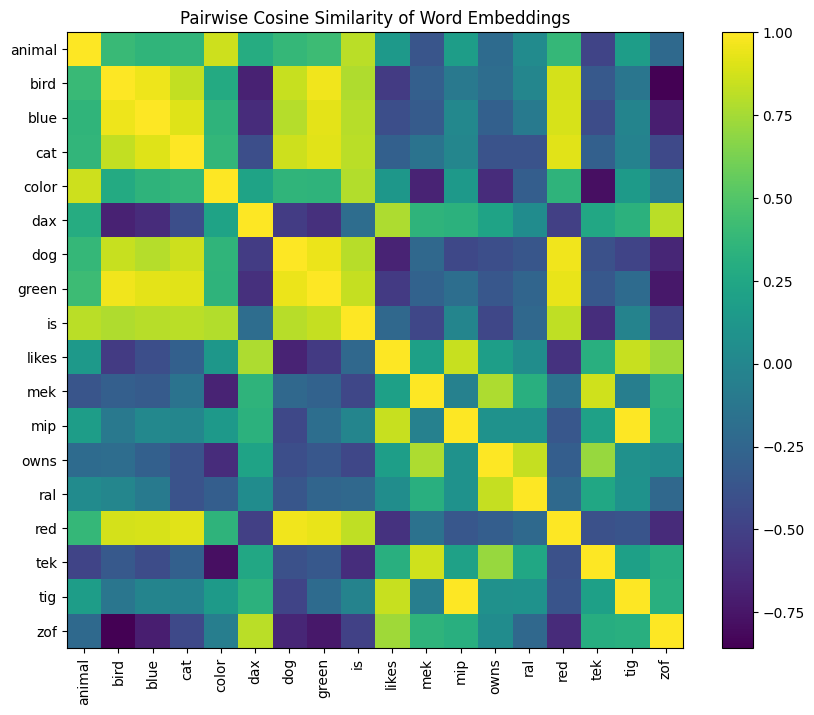

Epoch 400, Loss: 0.4623


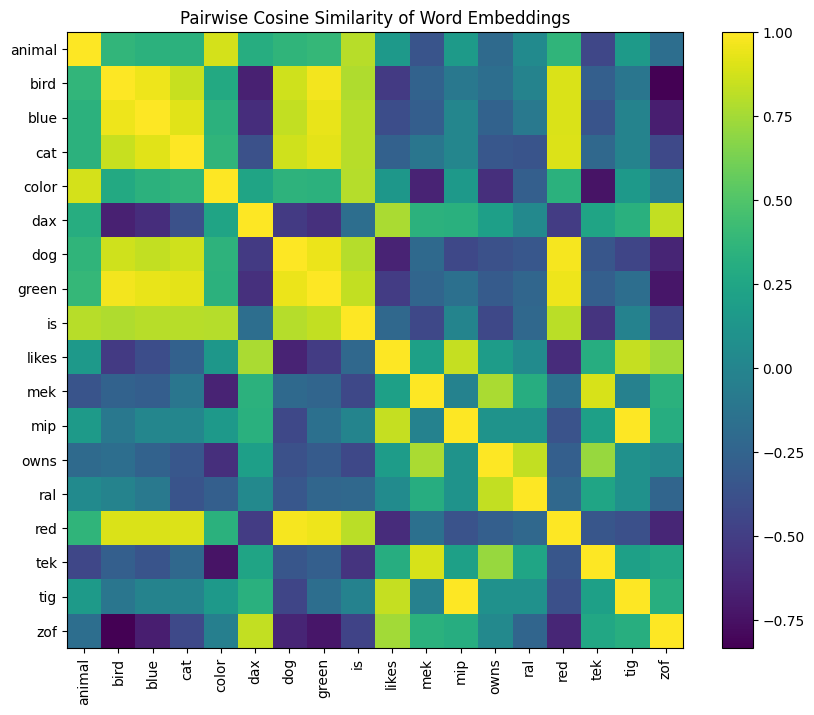

Epoch 500, Loss: 0.4055


In [43]:
# training loop, one batch in entire dataset
for epoch in range(epochs):
    optimizer.zero_grad()
    logits = model(x)  # (B, T, vocab_size)
    loss = torch.nn.functional.cross_entropy(logits.view(-1, vocab_size), y.view(-1))
    loss.backward()
    optimizer.step()

    if epoch % 100 == 0:
        with torch.no_grad():
            visualize_embeddings(model, vocabulary)
        print(f"Epoch {epoch}, Loss: {loss.item():.4f}")

Even though it is only the next word predition (cat predicting is, is predicting animal) animal and cat are close to each other, but not very close, as is still requires to be simmilar to colors. Therefore color red is as similar to animal as bird is. </br>
While dax is very similar to likes (tig likes dax), it is also very simmilar to zof (tig likes zof) but not to so much to tig because dax and zof are used always with likes, but not always with tig.</br>
This is very much a statistcal usage propability. 